# LSMC pricing of Asian options under Vasicek rates: walkthrough

This notebook goes through the method of the paper step by step with the `lsmc_asian` package:

1. the model and its exact simulation,
2. checks against closed-form prices,
3. the European-exercise arithmetic Asian option and variance reduction,
4. the Bermudan-exercise Asian option priced by least-squares Monte Carlo,
5. the S&P 500 empirical application.

Every random number comes from a seeded generator, so re-running the notebook gives the same output.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lsmc_asian import (AsianOption, MarketModel, VanillaOption, black_scholes, european_price,
                        geometric_asian_price, price_european, price_lsmc, zero_coupon_bond)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEED = 20240914
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Model

Risk-neutral dynamics:

$$dr_t = \kappa(\theta - r_t)\,dt + \sigma_r\,dW^r_t, \qquad \frac{dS_t}{S_t} = (r_t - q)\,dt + \sigma_S\,dW^S_t, \qquad d\langle W^r, W^S\rangle_t = \rho\,dt.$$

Over each step the new short rate, the integral of the rate over the step and the Brownian increment of the asset are jointly Gaussian, so the simulation is exact (no Euler error) and the realised discount factor $D_t = e^{-\int_0^t r_u du}$ comes out of the same draw. Base case: the generic parameters of the paper's appendix.

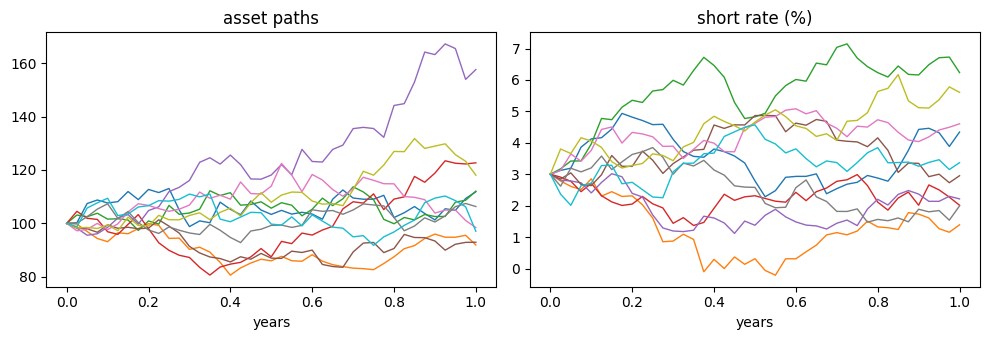

In [2]:
m = MarketModel(s0=100.0, sigma_s=0.20, r0=0.03, kappa=0.10, theta=0.05, sigma_r=0.02)
T, N, K = 1.0, 40, 100.0
paths = m.simulate(T, N, 10_000, np.random.default_rng(SEED))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(paths.times, paths.spot[:10].T, lw=1)
axes[0].set(title="asset paths", xlabel="years")
axes[1].plot(paths.times, 100 * paths.short_rate[:10].T, lw=1)
axes[1].set(title="short rate (%)", xlabel="years")
plt.tight_layout()

## 2. Checks against closed forms

The log asset price and the integrated rate are jointly Gaussian, which gives exact prices for the zero-coupon bond, the European option and the discretely monitored geometric-average Asian option, all with stochastic rates. The simulation must reproduce them within Monte Carlo error.

In [3]:
rng = np.random.default_rng(SEED + 1)
d_T = paths.discount[:, -1]
geo_mc = price_european(m, AsianOption(K, "call", "geometric"), T, N, 200_000, rng, antithetic=True)
eur_mc = price_european(m, VanillaOption(K, "call"), T, N, 200_000, rng, antithetic=True)
checks = pd.DataFrame([
    ["zero-coupon bond P(0,T)", zero_coupon_bond(m, T), d_T.mean(), d_T.std() / np.sqrt(d_T.size)],
    ["geometric Asian call", geometric_asian_price(m, K, T, N), geo_mc.price, geo_mc.std_error],
    ["European call", european_price(m, K, T), eur_mc.price, eur_mc.std_error],
], columns=["quantity", "closed form", "Monte Carlo", "std error"])
checks["z"] = (checks["Monte Carlo"] - checks["closed form"]) / checks["std error"]
checks

,quantity,closed form,Monte Carlo,std error,z
0,"zero-coupon bond P(0,T)",0.9696,0.9698,0.0001,1.7045
1,geometric Asian call,5.2062,5.2255,0.0125,1.5484
2,European call,9.4711,9.4563,0.0234,-0.6315


With $\sigma_r = 0$ the rate is deterministic and the closed forms reduce to Black-Scholes and to the discrete Kemna-Vorst formula (both covered by the test suite).

In [4]:
flat = MarketModel(s0=100, sigma_s=0.2, r0=0.05, kappa=1.0, theta=0.05, sigma_r=0.0)
european_price(flat, 100, 1.0), black_scholes(100, 100, 1.0, 0.05, 0.2)

(10.4505835721856, 10.450583572185565)

## 3. Arithmetic Asian option, European exercise

No closed form exists, so it is priced by Monte Carlo. Two variance-reduction techniques:

* **antithetic variates**: each normal draw is also used with its sign flipped;
* **control variate**: the geometric-average option on the same paths, whose exact price is known. The two payoffs are almost perfectly correlated.

The variance reduction factor is (plain standard error / reduced standard error)$^2$, i.e. how many times more plain paths would be needed for the same accuracy.

In [5]:
arith = AsianOption(K, "call", "arithmetic")
rows = []
for label, anti, cv in [("plain", False, False), ("antithetic", True, False),
                        ("control variate", False, True), ("antithetic + control variate", True, True)]:
    est = price_european(m, arith, T, N, 10_000, np.random.default_rng(SEED + 2), antithetic=anti, control_variate=cv)
    rows.append([label, est.price, est.std_error])
vr = pd.DataFrame(rows, columns=["method", "price", "std error"])
vr["variance reduction"] = (vr["std error"].iloc[0] / vr["std error"]) ** 2
vr

,method,price,std error,variance reduction
0,plain,5.5222,0.0803,1.0000
1,antithetic,5.4063,0.0584,1.8911
2,control variate,5.4062,0.0022,1329.8572
3,antithetic + control variate,5.4065,0.0022,1357.0620


## 4. Bermudan-exercise Asian option: least-squares Monte Carlo

If the holder may exercise on any monitoring date $t_j$ and receive $(A_j - K)^+$, with $A_j$ the average to date, the price is an optimal-stopping problem. LSMC (Longstaff and Schwartz, 2001) works backwards: on each date it regresses the realised, pathwise-discounted future cash flow of the in-the-money paths on polynomials in the state $(S_j, A_j, r_j)$, and exercises where the immediate payoff beats the fitted continuation value.

The in-sample estimate reuses the fitting paths, so its bias can go either way. The out-of-sample estimate applies the frozen rule to independent paths; a feasible rule cannot beat the optimal one, so it is a lower bound on the price up to Monte Carlo noise, and it is the number to report.

First, the engine on the standard benchmark of the original paper: an American put, $S_0=36$, $K=40$, $r=6\%$, $\sigma=20\%$, $T=1$, 50 exercise dates. The finite-difference value is 4.478.

In [6]:
bench = MarketModel(s0=36, sigma_s=0.2, r0=0.06, kappa=1.0, theta=0.06, sigma_r=0.0)
res = price_lsmc(bench, VanillaOption(40, "put"), 1.0, 50, 50_000, np.random.default_rng(SEED + 3),
                 degree=3, antithetic=True, n_paths_out_of_sample=50_000)
print(f"in-sample {res.in_sample.price:.4f} ± {res.in_sample.std_error:.4f}, "
      f"out-of-sample {res.out_of_sample.price:.4f} ± {res.out_of_sample.std_error:.4f}  (reference 4.478)")

in-sample 4.4569 ± 0.0086, out-of-sample 4.4659 ± 0.0086  (reference 4.478)


Now the Bermudan arithmetic Asian call under Vasicek rates, with and without the geometric control variate:

In [7]:
rows = []
for cv in (False, True):
    res = price_lsmc(m, arith, T, N, 10_000, np.random.default_rng(SEED + 4), antithetic=True,
                     n_paths_out_of_sample=10_000, control_variate=cv)
    for which, est in [("in-sample", res.in_sample), ("out-of-sample", res.out_of_sample), ("European exercise", res.european)]:
        rows.append(["with CV" if cv else "no CV", which, est.price, est.std_error])
pd.DataFrame(rows, columns=["control variate", "estimate", "price", "std error"])

,control variate,estimate,price,std error
0,no CV,in-sample,5.9848,0.0539
1,no CV,out-of-sample,6.0101,0.0542
2,no CV,European exercise,5.4084,0.0573
3,with CV,in-sample,5.9834,0.0189
4,with CV,out-of-sample,5.9509,0.0186
5,with CV,European exercise,5.4068,0.0021


## 5. S&P 500 application

`scripts/download_data.py` fetches S&P 500 closes (Yahoo Finance) and Treasury yields (FRED) for 2015 to 2023; `scripts/calibrate.py` estimates the inputs. The calibrated file is committed, so this section runs without downloading anything.

In [8]:
calib = json.loads((ROOT / "data/calibrated/sp500_2015-2023_DGS10.json").read_text())
vas = calib["diagnostics"]["vasicek"]
print("valuation date", calib["valuation_date"])
pd.Series(calib["market"]).to_frame("value").assign(
    std_error=pd.Series({"kappa": vas["kappa_se"], "theta": vas["theta_se"], "sigma_r": vas["sigma_se"]}))

valuation date 2023-12-29


,value,std_error
s0,4769.8301,NaN
sigma_s,0.1314,NaN
r0,0.0388,NaN
kappa,0.2585,0.5042
theta,0.0305,0.0204
sigma_r,0.0085,0.0001
rho,0.1865,NaN
dividend_yield,0.0000,NaN


The mean-reversion speed is poorly determined on nine years of data (its bootstrap standard error is about twice the estimate). The 3-month yield cannot be fitted at all on this window: it trends from 0% to 5.4% and the AR(1) slope exceeds one. Like the paper, the calibration therefore uses the 10-year yield as the rate input.

If the raw data has been downloaded, plot it:

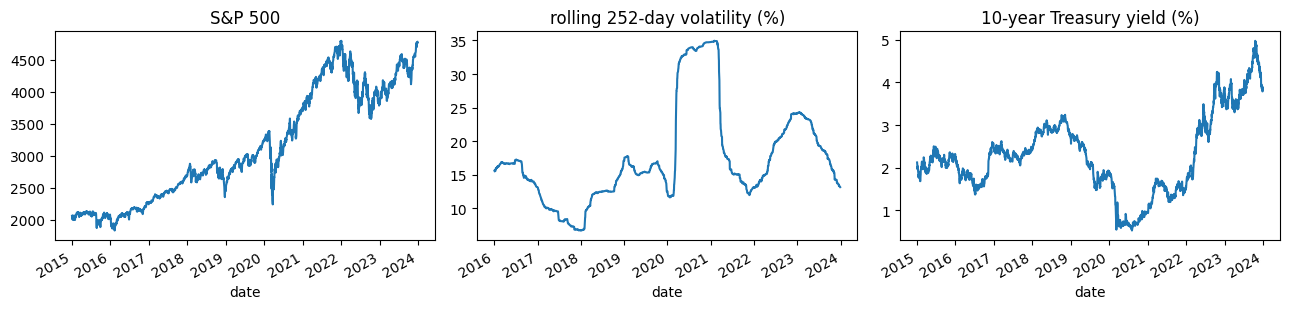

In [9]:
raw = ROOT / "data/raw"
if (raw / "sp500_close.csv").exists():
    from lsmc_asian.calibration import rolling_volatility
    from lsmc_asian.data import load_rate, load_sp500
    px, r10 = load_sp500(raw / "sp500_close.csv"), load_rate(raw / "fred_DGS10.csv")
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
    px.plot(ax=axes[0], title="S&P 500")
    (100 * rolling_volatility(px)).plot(ax=axes[1], title="rolling 252-day volatility (%)")
    (100 * r10).plot(ax=axes[2], title="10-year Treasury yield (%)")
    plt.tight_layout()
else:
    print("run scripts/download_data.py to plot the raw series")

Prices at the calibrated parameters and at the parameter values of the paper's Table 6-1, as produced by `scripts/run_experiment.py` (committed in `results/`):

In [10]:
cols = ["product", "method", "price", "std_error", "ci95_low", "ci95_high"]
for name in ["paper_table_6_1", "sp500_calibrated"]:
    print(name)
    display(pd.read_csv(ROOT / "results" / name / "pricing.csv")[cols])

paper_table_6_1


,product,method,price,std_error,ci95_low,ci95_high
0,arithmetic Asian call (European exercise),MC,181.1140,2.8928,175.4450,186.7840
1,arithmetic Asian call (European exercise),MC + antithetic,180.0110,2.2163,175.6670,184.3550
2,arithmetic Asian call (European exercise),MC + control variate,183.1070,0.0837,182.9430,183.2710
3,arithmetic Asian call (European exercise),MC + antithetic + control variate,183.1030,0.0780,182.9500,183.2560
4,geometric Asian call (European exercise),closed form,175.7700,0.0000,175.7700,175.7700
5,geometric Asian call (European exercise),MC + antithetic,173.3400,2.1645,169.0980,177.5830
6,European call,closed form,341.9970,0.0000,341.9970,341.9970
7,European call,MC + antithetic,341.7680,4.2373,333.4620,350.0730
8,arithmetic Asian call (Bermudan exercise),"LSMC, in-sample",204.0740,2.1587,199.8430,208.3050
9,arithmetic Asian call (Bermudan exercise),"LSMC, out-of-sample",206.2660,2.2348,201.8850,210.6460


sp500_calibrated


,product,method,price,std_error,ci95_low,ci95_high
0,arithmetic Asian call (European exercise),MC,156.0110,2.2559,151.5900,160.4330
1,arithmetic Asian call (European exercise),MC + antithetic,156.1290,1.6759,152.8440,159.4140
2,arithmetic Asian call (European exercise),MC + control variate,159.0070,0.0448,158.9190,159.0940
3,arithmetic Asian call (European exercise),MC + antithetic + control variate,159.0420,0.0456,158.9520,159.1310
4,geometric Asian call (European exercise),closed form,154.6500,0.0000,154.6500,154.6500
5,geometric Asian call (European exercise),MC + antithetic,157.8320,1.6378,154.6220,161.0420
6,European call,closed form,312.5270,0.0000,312.5270,312.5270
7,European call,MC + antithetic,313.0240,3.1004,306.9480,319.1010
8,arithmetic Asian call (Bermudan exercise),"LSMC, in-sample",164.8320,1.5519,161.7900,167.8740
9,arithmetic Asian call (Bermudan exercise),"LSMC, out-of-sample",170.9890,1.6180,167.8180,174.1610


## Reproducing everything

```
python scripts/download_data.py
python scripts/calibrate.py
python scripts/run_experiment.py configs/*.json
python scripts/make_figures.py
pytest
```